# Análisis exploratorio (EDA)

Exploración de los datos que justifica las decisiones de `features.py`, `train.ipynb` y `predict.ipynb`. El detalle de cada experimento está en `trabajo_realizado/BITACORA.md`; las EDA originales, en `trabajo_realizado/01_eda.ipynb` y `trabajo_realizado/06_eda_nuevas.ipynb`.

## 1. Carga y forma de los datos

Publicaciones de MercadoLibre Argentina (2013–2015), una por línea en formato JSON (`.jsonlines`). El objetivo es predecir `condition` (`new` / `used`).

In [1]:
import pandas as pd

train = pd.read_json("data/train_data.jsonlines", lines=True)
test = pd.read_json("data/test_data.jsonlines", lines=True)

print("train:", train.shape, "| test:", test.shape)
print("Solo en train:", sorted(set(train.columns) - set(test.columns)))
print("Solo en test:", sorted(set(test.columns) - set(train.columns)))

train: (70000, 45) | test: (30000, 44)
Solo en train: ['condition']
Solo en test: []


In [2]:
def tipo_dominante(serie):
    """Tipo de Python más frecuente entre los valores no nulos de una columna."""
    tipos = serie.dropna().map(lambda valor: type(valor).__name__)
    return tipos.value_counts().idxmax() if len(tipos) else "todo nulo"

tipos = train.drop(columns="condition").apply(tipo_dominante)
print(tipos.value_counts().to_string(), "\n")

anidadas = tipos[tipos.isin(["dict", "list"])].index
for columna in anidadas:
    print(f"{columna:35s} {tipos[columna]:5s} ejemplo: {str(train.loc[0, columna])[:90]}")

str          18
list          9
float         5
int           4
dict          2
todo nulo     2
bool          2
Timestamp     2 

seller_address                      dict  ejemplo: {'country': {'name': 'Argentina', 'id': 'AR'}, 'state': {'name': 'Buenos Aires', 'id': 'AR
sub_status                          list  ejemplo: []
deal_ids                            list  ejemplo: []
shipping                            dict  ejemplo: {'local_pick_up': True, 'methods': [], 'tags': [], 'free_shipping': False, 'mode': 'not_sp
non_mercado_pago_payment_methods    list  ejemplo: [{'description': 'Transferencia bancaria', 'id': 'MLATB', 'type': 'G'}, {'description': 'A
variations                          list  ejemplo: []
attributes                          list  ejemplo: []
tags                                list  ejemplo: ['dragged_bids_and_visits']
coverage_areas                      list  ejemplo: []
descriptions                        list  ejemplo: ["{'id': 'MLA3911152707-935835266'}"]
pictur

**Lo que muestra la sección 1 (confirmado):**
- Train 70.000 × 45 y test 30.000 × 44: la única columna que falta en el test es el target `condition`.
- 11 columnas no son planas: 2 `dict` (`seller_address`, `shipping`) y 9 listas (`pictures`, `tags`, `non_mercado_pago_payment_methods`, `attributes`, `variations`, `descriptions`, `deal_ids`, `sub_status`, `coverage_areas`). Un modelo no puede usarlas así: hay que **aplanarlas** en columnas simples (un campo del dict, el largo de la lista, un flag por valor). Eso hace `aplanar_anidadas` en `features.py`.
- 2 columnas están completamente vacías (`differential_pricing`, `subtitle`): se descartan.
- `start_time` y `stop_time` las lee pandas como fecha (`Timestamp`); de ahí sale después la duración de la publicación (sección 9).

## 2. El target: `condition`

Se mira qué tan balanceadas están las clases. Si una clase fuera muy minoritaria, la accuracy engañaría y habría que pensar en técnicas de `material/datasets desbalanceados/Tratamiento de datasets desbalanceados.pdf` (pesos de clase, under/over-sampling).

`y` vale 1 si la publicación es `new` y 0 si es `used` (la misma convención que en `train.ipynb`).

           filas     %
condition             
new        37588  53.7
used       32412  46.3

Accuracy de predecir siempre 'new' (piso a superar): 0.5370


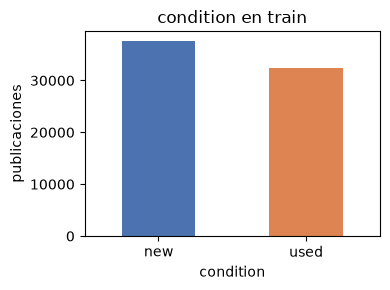

In [3]:
import numpy as np
import matplotlib.pyplot as plt

y = (train["condition"] == "new").astype(int)

conteo = train["condition"].value_counts()
print(pd.DataFrame({"filas": conteo, "%": (conteo / len(train) * 100).round(1)}))
print(f"\nAccuracy de predecir siempre 'new' (piso a superar): {y.mean():.4f}")

fig, ax = plt.subplots(figsize=(4, 3))
conteo.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], rot=0)
ax.set_ylabel("publicaciones")
ax.set_title("condition en train")
plt.tight_layout()
plt.show()

**Lo que muestra la sección 2:**
- 37.588 `new` (53,7%) y 32.412 `used` (46,3%): **casi balanceado**. No hace falta ninguna técnica de desbalance, y la accuracy (la métrica de Kaggle) es una medida razonable.
- Predecir siempre `new` da 0,537: ese es el piso. El baseline de regresión logística con 5 variables llega a 0,822 y el modelo final a 0,9435.
- Para que cada fold de la CV tenga la misma proporción de clases se usa `StratifiedKFold`.

## 3. Datos faltantes

Para cada columna: % de nulos en train y en test, y % de listas vacías (una lista vacía es otra forma de "no hay dato"). Para las columnas con nulos se compara el % de `new` cuando el dato está y cuando falta: si cambia mucho, **que falte es información** y conviene un flag de presencia (*indicador de faltante*, `material/Variables Categóricas, Datos Faltantes y Feature Engineering/Tratamiento-de-variables-categóricas.pdf`, sección "Datos Faltantes").

In [4]:
faltantes = pd.DataFrame({
    "nulos_train_%": train.drop(columns="condition").isna().mean() * 100,
    "nulos_test_%": test.isna().mean() * 100,
})
es_lista = tipos == "list"
faltantes["listas_vacias_train_%"] = np.nan
faltantes.loc[es_lista, "listas_vacias_train_%"] = [
    train[c].map(lambda v: isinstance(v, list) and len(v) == 0).mean() * 100 for c in tipos[es_lista].index]
con_algo = faltantes[(faltantes["nulos_train_%"] > 0) | (faltantes["listas_vacias_train_%"] > 0)]
con_algo.sort_values(["nulos_train_%", "listas_vacias_train_%"], ascending=False).round(1)

,nulos_train_%,nulos_test_%,listas_vacias_train_%
differential_pricing,100.0,100.0,NaN
subtitle,100.0,100.0,NaN
catalog_product_id,100.0,100.0,NaN
original_price,99.9,99.9,NaN
official_store_id,99.2,99.2,NaN
video_id,97.0,97.1,NaN
warranty,60.9,60.8,NaN
parent_item_id,23.0,23.2,NaN
coverage_areas,0.0,0.0,100.0
deal_ids,0.0,0.0,99.7


In [5]:
filas = []
for columna in ["original_price", "official_store_id", "video_id", "warranty", "parent_item_id", "catalog_product_id"]:
    presente = train[columna].notna()
    filas.append({
        "columna": columna,
        "filas con dato": int(presente.sum()),
        "% new con dato": round(y[presente].mean() * 100, 1) if presente.any() else np.nan,
        "% new sin dato": round(y[~presente].mean() * 100, 1),
    })
pd.DataFrame(filas).set_index("columna")

,filas con dato,% new con dato,% new sin dato
columna,,,
original_price,103,100.0,53.6
official_store_id,575,97.0,53.3
video_id,2102,77.0,53.0
warranty,27342,62.0,48.4
parent_item_id,53934,53.4,54.8
catalog_product_id,7,28.6,53.7


**Lo que muestra la sección 3:**
- 8 columnas tienen nulos, con el mismo % en train y en test. Las 3 vacías (`differential_pricing`, `subtitle`, `catalog_product_id`, esta última con 7 valores) se descartan.
- En las otras 5, **que el dato esté es información**, y su valor crudo no sirve (son ids o texto libre). Por eso `aplanar_anidadas` las reemplaza por un flag de presencia:

| Columna | Flag | % `new` con dato | % `new` sin dato |
|---|---|---|---|
| `original_price` (precio antes del descuento) | `tiene_descuento` | 100,0 (103 filas) | 53,6 |
| `official_store_id` | `es_tienda_oficial` | 97,0 | 53,3 |
| `video_id` | `tiene_video` | 77,0 | 53,0 |
| `warranty` | `tiene_garantia` (y el texto, en el modelo de texto) | 62,0 | 48,4 |
| `parent_item_id` | `tiene_parent_item` | 53,4 | 54,8 |

- Las listas no tienen nulos, pero muchas vienen vacías (`coverage_areas` 100%, `deal_ids` 99,7%, `sub_status` 99,0%, `variations` 91,8%, `attributes` 87,6%). Se resumen en **conteos** (`n_fotos`, `n_atributos`, `n_variaciones`, `n_metodos_pago`) o **flags** (`tiene_oferta`, `tiene_sub_status`, un `tag_*` por cada tag); `coverage_areas` se descarta.
- No hace falta imputar: los flags y los conteos no tienen nulos. Las features de fotos que pueden faltar (0,8% sin fotos) las manejan los árboles, que aceptan `NaN`.

## 4. Outliers

Se miran el precio y las cantidades. Hay dos monedas (`currency_id`: pesos y dólares), así que los percentiles del precio se calculan **por moneda**: mezclar las dos escalas haría que los precios en dólares parezcan bajos y los en pesos, altos.

Técnica del material: *winsorizing* (poner un techo en un percentil en lugar de borrar la fila), `material/outliers/Identificacion y tratamiento de Outliers y Bootstrap.pdf`.

In [6]:
percentiles = train.groupby("currency_id")["price"].describe(percentiles=[0.5, 0.99, 0.995])
percentiles = percentiles[["count", "50%", "99%", "99.5%", "max"]]
techo = train.groupby("currency_id")["price"].transform(lambda p: p.quantile(0.995))
percentiles["filas sobre el 99,5%"] = (train["price"] > techo).groupby(train["currency_id"]).sum()
print(percentiles.round(0).to_string())

print("\nLos 8 precios más altos en pesos:")
print(train[train["currency_id"] == "ARS"].nlargest(8, "price")[["price", "title", "condition"]].to_string())

print("\nprice == base_price en", f"{(train['price'] == train['base_price']).mean():.2%}", "de las filas")
for columna in ["initial_quantity", "available_quantity", "sold_quantity"]:
    print(f"{columna:20s} mediana {train[columna].median():>6.0f} | p99 {train[columna].quantile(0.99):>6.0f} | "
          f"máx {train[columna].max():>6.0f} | filas = 9999: {(train[columna] == 9999).sum()}")

               count       50%        99%      99.5%           max  filas sobre el 99,5%
currency_id                                                                             
ARS          69601.0     250.0    90000.0   180000.0  2.222222e+09                   342
USD            399.0  105000.0  1544500.0  3981440.0  1.111111e+07                     2

Los 8 precios más altos en pesos:
              price                                                   title condition
42296  2.222222e+09  Oryzias Rice Fish Ideal Acuarios Plantados Oferta X 10       new
63407  1.111111e+09                                                   Campo      used
883    1.234568e+08                                     Berlingo Multispace      used
33346  1.121111e+08                             Vendemos Su Auto - Consulte      used
14924  1.111111e+07    Equipo Enganchado Scania 96 Con Acoplado Bonano 2004      used
27391  1.111111e+07                                        River Plate 2015       new
37101  

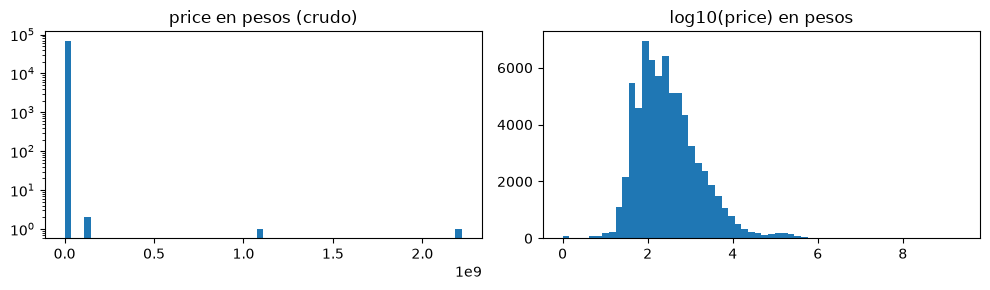

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
ars = train[train["currency_id"] == "ARS"]
axes[0].hist(ars["price"], bins=60)
axes[0].set_title("price en pesos (crudo)")
axes[0].set_yscale("log")
axes[1].hist(np.log10(ars["price"]), bins=60)
axes[1].set_title("log10(price) en pesos")
plt.tight_layout()
plt.show()

**Lo que muestra la sección 4:**
- **Precio:** en pesos la mediana es $250 y el percentil 99,5 es $180.000, pero el máximo es $2.222.222.222. Los precios más altos son **errores de carga** evidentes (dígitos repetidos: 2222222222, 1111111111, 123456790), en publicaciones como un pez de acuario o "Campo".
- Las **dos monedas** tienen escalas muy distintas (mediana en dólares: 105.000), por eso el techo se calcula **por moneda**.
- **Tratamiento (`CapeoPorMoneda` en `features.py`):** *winsorizing* al percentil 99,5 de cada moneda: lo que supera el techo pasa a valer el techo. Afecta a 344 filas (342 en pesos y 2 en dólares, 0,5%). Se usa 99,5 y no el 5/95 del ejemplo del material porque el problema está en una cola muy chica; un corte en 95 recortaría precios legítimos. El techo se aprende **dentro del `Pipeline`**, con el train de cada fold.
- Después del capeo se usa `log(price)`: el precio sigue muy asimétrico (gráfico de la izquierda) y en escala logarítmica queda más simétrico (derecha).
- `price` = `base_price` en el 99,97% de las filas: se usa una sola.
- **Cantidades:** el máximo 9999 es el tope de stock de MercadoLibre (71 filas en `initial_quantity`), no un error. Se dejan, y `available_quantity` entra como `log1p` (puede valer 0).

## 5. Numéricas y flags contra `condition`

Para ver cada variable con la misma forma que la usa el modelo, se aplican las dos primeras funciones determinísticas de `features.py` (las mismas que usan `train.ipynb` y `predict.ipynb`): `aplanar_anidadas` (conteos y flags de las columnas anidadas) y `agregar_features_contenido` (fotos, fechas, garantía como texto y duración).

- **Numéricas:** mediana en `new` y en `used`.
- **Flags (sí/no):** % de filas con el flag y % de `new` con y sin el flag.

In [8]:
from features import aplanar_anidadas, agregar_features_contenido

plano = agregar_features_contenido(aplanar_anidadas(train))
plano_test = agregar_features_contenido(aplanar_anidadas(test))
plano["log_price"] = np.log(plano["price"].clip(lower=1))

numericas = ["log_price", "initial_quantity", "available_quantity", "sold_quantity", "n_fotos",
             "n_metodos_pago", "n_atributos", "n_variaciones", "foto_log_px_primera", "gap_actualizacion"]
medianas = plano.groupby("condition")[numericas].median().T
medianas["% filas > 0"] = ((plano[numericas] > 0).mean() * 100).round(1)
print(medianas.round(2).to_string())

condition              new   used  % filas > 0
log_price             5.86   5.01         99.9
initial_quantity      2.00   1.00        100.0
available_quantity    2.00   1.00        100.0
sold_quantity         0.00   0.00         17.0
n_fotos               3.00   2.00         99.2
n_metodos_pago        2.00   1.00         69.4
n_atributos           0.00   0.00         12.4
n_variaciones         0.00   0.00          8.2
foto_log_px_primera  13.05  13.80         99.1
gap_actualizacion     0.00   0.00         98.7


In [9]:
flags = ["automatic_relist", "accepts_mercadopago", "free_shipping", "local_pick_up", "tiene_oferta",
         "tiene_garantia", "tiene_video", "es_tienda_oficial", "tiene_descuento", "tiene_parent_item",
         "tiene_sub_status", "tag_dragged_bids_and_visits", "tag_good_quality_thumbnail", "tag_poor_quality_thumbnail",
         "tag_free_relist", "tag_dragged_visits"]
tabla_flags = pd.DataFrame({
    "% filas con flag": [plano[f].astype(bool).mean() * 100 for f in flags],
    "% new con flag": [y[plano[f].astype(bool)].mean() * 100 for f in flags],
    "% new sin flag": [y[~plano[f].astype(bool)].mean() * 100 for f in flags],
}, index=flags)
tabla_flags["diferencia"] = tabla_flags["% new con flag"] - tabla_flags["% new sin flag"]
tabla_flags.sort_values("diferencia", key=abs, ascending=False).round(1)

,% filas con flag,% new con flag,% new sin flag,diferencia
tag_free_relist,0.3,5.5,53.8,-48.4
tiene_descuento,0.1,100.0,53.6,46.4
tag_poor_quality_thumbnail,0.0,100.0,53.7,46.3
tiene_oferta,0.3,98.9,53.6,45.3
automatic_relist,4.7,95.4,51.6,43.8
es_tienda_oficial,0.8,97.0,53.3,43.7
free_shipping,3.0,93.2,52.5,40.7
tag_good_quality_thumbnail,1.7,89.4,53.1,36.3
accepts_mercadopago,97.8,54.4,22.5,31.9
tag_dragged_visits,0.8,25.4,53.9,-28.5


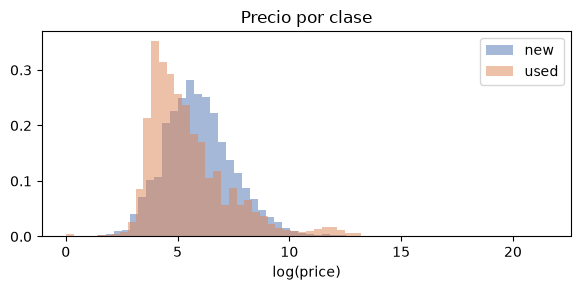

Correlación price vs base_price: 1.0 | initial_quantity vs available_quantity: 0.9999


In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
for clase, color in [("new", "#4C72B0"), ("used", "#DD8452")]:
    ax.hist(plano.loc[plano["condition"] == clase, "log_price"], bins=60, alpha=0.5, density=True, label=clase, color=color)
ax.set_xlabel("log(price)")
ax.set_title("Precio por clase")
ax.legend()
plt.tight_layout()
plt.show()

print("Correlación price vs base_price:", train["price"].corr(train["base_price"]).round(4),
      "| initial_quantity vs available_quantity:", train["initial_quantity"].corr(train["available_quantity"]).round(4))

**Lo que muestra la sección 5:**
- **Precio:** las `new` son más caras (mediana de `log_price` 5,86 contra 5,01: unos $350 contra $150).
- **Cantidades y fotos:** las `new` tienen más stock (mediana 2 contra 1), más fotos (3 contra 2) y aceptan más métodos de pago (2 contra 1).
- **Tamaño de la primera foto:** es más grande en las `used` (`foto_log_px_primera` 13,80 contra 13,05: ~1 millón de píxeles contra ~0,5). **Hipótesis, no verificada:** las fotos de usados las saca el vendedor con su cámara, y las de nuevos son fotos de catálogo.
- **Flags:** las señales más fuertes son las de "vendedor profesional": oferta (98,9% `new`), relist automático (95,4%), tienda oficial (97,0%), envío gratis (93,2%), descuento (100%), miniatura de buena calidad (89,4%). Pero cada una cubre a pocas filas (0,1% a 4,7%). Al revés, `tag_free_relist` (5,5% `new`) y `tag_dragged_visits` (25,4%) marcan `used`. No aceptar MercadoPago (2,2% de las filas) da 22,5% `new`.
- **Sin señal propia:** `tag_dragged_bids_and_visits` (53,7 contra 53,6). Se deja porque no molesta a los árboles.
- **Redundantes:** `price`/`base_price` (correlación 1,0) e `initial_quantity`/`available_quantity` (0,9999). Los árboles toleran columnas redundantes; los modelos lineales de la `13_comparacion_modelos` usan una de cada par.
- **Lectura general:** ninguna variable numérica sola separa bien las clases. La señal está repartida, y por eso funcionan los modelos de árboles con muchas features.

## 6. Categóricas contra `condition`

- **Pocas categorías** (`listing_type_id`, `buying_mode`, `shipping_mode`, `currency_id`, `status`): cantidad de filas y % de `new` en cada valor.
- **Columnas constantes:** una sola categoría no le enseña nada al modelo.
- **Muchas categorías** (`category_id`, `seller_id`): con miles de valores, *one-hot* crearía miles de columnas casi vacías. El material (`material/Variables Categóricas, Datos Faltantes y Feature Engineering/Tratamiento-de-variables-categóricas.pdf`) propone para eso **target encoding** (reemplazar cada categoría por el % de `new` de esa categoría), con resguardos para no usar la etiqueta de la propia fila.

In [11]:
for columna in ["listing_type_id", "buying_mode", "shipping_mode", "currency_id", "status"]:
    serie = plano[columna]
    tabla = pd.DataFrame({"filas": serie.value_counts(), "% new": (y.groupby(serie).mean() * 100).round(1)})
    print(f"--- {columna}\n{tabla.sort_values('filas', ascending=False).to_string()}\n")

print("Valores distintos de columnas candidatas a constantes:",
      {c: train[c].nunique() for c in ["site_id", "listing_source", "international_delivery_mode"]})

--- listing_type_id
                 filas  % new
listing_type_id              
bronze           44143   62.3
free             15047    7.3
silver            6363   80.0
gold_special      2134   98.4
gold              1713   86.6
gold_premium       587   54.2
gold_pro            13  100.0

--- buying_mode
             filas  % new
buying_mode              
buy_it_now   67926   54.6
classified    1532   22.5
auction        542   32.3

--- shipping_mode
               filas  % new
shipping_mode              
me2            36008   57.0
not_specified  31510   48.8
custom          2424   66.8
me1               58  100.0

--- currency_id
             filas  % new
currency_id              
ARS          69601   53.8
USD            399   38.1

--- status
                filas  % new
status                      
active          67032   53.0
paused           2952   69.2
closed             15   40.0
not_yet_active      1  100.0

Valores distintos de columnas candidatas a constantes: {'site_id': 1

category_id: 9570 valores distintos | mediana de filas por valor 2 | máximo 3180 | con 5 filas o menos: 75.4%
   con 20+ filas: 627 valores; con >= 90% o <= 10% new: 39.7% de esos valores (32.1% de sus filas)
seller_id: 27949 valores distintos | mediana de filas por valor 1 | máximo 655 | con 5 filas o menos: 93.3%
   con 20+ filas: 407 valores; con >= 90% o <= 10% new: 78.9% de esos valores (83.7% de sus filas)


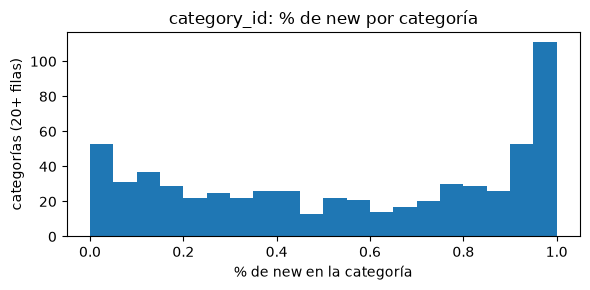

In [12]:
for columna in ["category_id", "seller_id"]:
    por_valor = pd.DataFrame({"filas": train.groupby(columna).size(), "pct_new": y.groupby(train[columna]).mean()})
    grandes = por_valor[por_valor["filas"] >= 20]
    extremos = ((grandes["pct_new"] >= 0.9) | (grandes["pct_new"] <= 0.1))
    print(f"{columna}: {len(por_valor)} valores distintos | mediana de filas por valor {por_valor['filas'].median():.0f} | "
          f"máximo {por_valor['filas'].max()} | con 5 filas o menos: {(por_valor['filas'] <= 5).mean():.1%}")
    print(f"   con 20+ filas: {len(grandes)} valores; con >= 90% o <= 10% new: {extremos.mean():.1%} de esos valores "
          f"({grandes.loc[extremos, 'filas'].sum() / grandes['filas'].sum():.1%} de sus filas)")

por_categoria = pd.DataFrame({"filas": train.groupby("category_id").size(), "pct_new": y.groupby(train["category_id"]).mean()})
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(por_categoria.loc[por_categoria["filas"] >= 20, "pct_new"], bins=20)
ax.set_xlabel("% de new en la categoría")
ax.set_ylabel("categorías (20+ filas)")
ax.set_title("category_id: % de new por categoría")
plt.tight_layout()
plt.show()

**Lo que muestra la sección 6:**
- **`listing_type_id` es la categórica chica más fuerte:** `free` 7,3% `new` (casi todo usado) contra `gold_special` 98,4% y `silver` 80,0%. Las publicaciones gratuitas son de particulares, y las pagas, de vendedores que venden nuevo.
- `buying_mode`: `classified` (22,5%) y `auction` (32,3%) son más de usados. `currency_id`: en dólares, 38,1% `new`. `status`: `paused` 69,2%.
- **Constantes:** `site_id`, `listing_source` e `international_delivery_mode` tienen un solo valor: se descartan.
- **Alta cardinalidad:**
  - `category_id`: 9.570 categorías, la mediana tiene 2 publicaciones y el 75,4% tiene 5 o menos. Entre las 627 con 20+ filas, el 39,7% es casi pura (≥ 90% o ≤ 10% `new`).
  - `seller_id`: 27.949 vendedores, la mediana tiene 1 publicación. Entre los 407 con 20+ filas, el **78,9%** es casi puro, con el 83,7% de sus filas.
- **Tratamiento:** one-hot solo para las 4 categóricas chicas (`listing_type_id`, `buying_mode`, `shipping_mode`, `seller_state`) en el HistGB. Para vendedor, categoría y sus combinaciones, **target encoding** con dos resguardos para que ninguna fila use su propia etiqueta:
  - `TargetEncoder` de scikit-learn con *cross-fitting* en el HistGB: cada fila se codifica con las otras 4/5 partes del train;
  - CatBoost con *ordered target statistics*: cada fila usa solo las filas anteriores en un orden al azar.

  Con tantas categorías chicas, los dos además **suavizan** hacia el promedio global.

  En el material está el target encoder en su versión simple; los resguardos (*cross-fitting*, suavizado, *ordered target statistics*) **no están en el material** (sección 6 de `trabajo_realizado/BITACORA.md`).

## 7. El vendedor (`seller_id`)

El vendedor es la variable que más sumó en todo el trabajo. Se mira:
- cuántas publicaciones tiene cada vendedor y qué tan "puros" son (si venden casi todo nuevo o casi todo usado);
- una **prueba simple sin modelo:** para cada publicación de un vendedor con 2 o más publicaciones, predecir la clase mayoritaria de **sus otras** publicaciones (sin mirar la propia: *leave-one-out*, el mismo resguardo de `VendedorEncoder` en `features.py`);
- cuántas filas del test tienen un vendedor (y una categoría) que ya aparece en el train.

In [13]:
vendedor = train["seller_id"]
filas_vendedor = vendedor.map(vendedor.value_counts())
suma_new_vendedor = y.groupby(vendedor).transform("sum")

# Leave-one-out: % de new de las OTRAS publicaciones del mismo vendedor
otros = filas_vendedor - 1
pct_otros = (suma_new_vendedor - y) / otros.replace(0, np.nan)
tiene_otros = otros > 0
prediccion = (pct_otros[tiene_otros] >= 0.5).astype(int)
print(f"Vendedores distintos: {vendedor.nunique()} | publicaciones por vendedor: mediana {vendedor.value_counts().median():.0f}, "
      f"máximo {vendedor.value_counts().max()}")
print(f"Filas cuyo vendedor tiene otras publicaciones en train: {tiene_otros.mean():.1%}")
print(f"Accuracy de 'la clase mayoritaria de sus otras publicaciones' en esas filas: {(prediccion == y[tiene_otros]).mean():.4f}")

pct_vendedor = y.groupby(vendedor).mean()
n_vendedor = vendedor.value_counts()
con5 = pct_vendedor[n_vendedor[pct_vendedor.index] >= 5]
print(f"Vendedores con 5+ publicaciones: {len(con5)}; de ellos, 100% new: {(con5 == 1).mean():.1%}, "
      f"100% used: {(con5 == 0).mean():.1%}, mezcla: {((con5 > 0) & (con5 < 1)).mean():.1%}")

for columna in ["seller_id", "category_id"]:
    print(f"Filas del test con {columna} visto en train: {test[columna].isin(set(train[columna])).mean():.1%}")

Vendedores distintos: 27949 | publicaciones por vendedor: mediana 1, máximo 655
Filas cuyo vendedor tiene otras publicaciones en train: 71.5%
Accuracy de 'la clase mayoritaria de sus otras publicaciones' en esas filas: 0.9234


Vendedores con 5+ publicaciones: 2338; de ellos, 100% new: 46.8%, 100% used: 25.1%, mezcla: 28.0%
Filas del test con seller_id visto en train: 71.6%
Filas del test con category_id visto en train: 94.7%


**Lo que muestra la sección 7:**
- La mayoría de los vendedores es "puro": entre los 2.338 con 5+ publicaciones, el 46,8% vende **solo** `new`, el 25,1% **solo** `used` y apenas el 28,0% mezcla.
- **La prueba sin modelo:** para el 71,5% de las filas cuyo vendedor tiene otras publicaciones, "predecir lo que suele vender ese vendedor" (sin mirar la propia fila) ya da **0,9234** de accuracy. Por eso el vendedor fue lo que más sumó (+0,037 en `04_vendedor`, Fase A de la bitácora).
- **El test se parece:** el 71,6% de las filas del test tiene un vendedor que aparece en el train, casi lo mismo que el 71,5% de la prueba de arriba. Así que la CV mide bien cuánto ayuda el vendedor. El 94,7% del test tiene una categoría vista en el train.
- Para el ~28% restante (vendedores nuevos) el modelo depende del texto, el precio y el resto de las features. Ahí es donde más ayudó BETO (Fase T: de 0,8931 a 0,8962 en las filas sin historial).
- **Por qué *leave-one-out*:** si cada fila usara el % de `new` de su vendedor **incluyéndose a sí misma**, un vendedor con una sola publicación tendría 100% o 0% justo según su propia etiqueta. Eso es *leakage*: en la CV parece perfecto y en el test no se repite.

## 8. El texto: título y garantía

Se cuenta, para cada palabra que aparece en al menos 300 títulos, en cuántos títulos aparece y qué % de esos son `new`. `CountVectorizer(binary=True)` arma una columna por palabra con 1 si el título la tiene. `strip_accents="unicode"` hace que "envío" y "envio" cuenten como la misma palabra.

En el modelo el texto entra de dos formas: TF-IDF del título y la probabilidad de un modelo de texto (regresión logística sobre TF-IDF de título y garantía, promediada con BETO). **TF-IDF y n-gramas no están en el material** (se explicaron en `trabajo_realizado/03_titulo.ipynb`); los transformers como BETO, sí: SIA `material/redes neuronales/S12 - Redes Neuronales - NLP.pdf` (el *fine-tuning* no).

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

contador = CountVectorizer(binary=True, min_df=300, strip_accents="unicode")
presencia = contador.fit_transform(train["title"])
palabras = pd.DataFrame({
    "títulos": np.asarray(presencia.sum(axis=0)).ravel(),
    "% new": np.asarray(presencia.T @ y.to_numpy()).ravel() / np.asarray(presencia.sum(axis=0)).ravel() * 100,
}, index=contador.get_feature_names_out())
print(f"{len(palabras)} palabras en 300+ títulos\n")
print("Más asociadas a new:\n", palabras.sort_values("% new", ascending=False).head(12).round(1).to_string(), "\n")
print("Más asociadas a used:\n", palabras.sort_values("% new").head(12).round(1).to_string())

130 palabras en 300+ títulos

Más asociadas a new:
               títulos  % new
amortiguador      507  100.0
delantero         521   99.2
freno             419   99.0
trasero           543   98.9
kit              1012   96.9
vw                329   91.5
bateria           504   91.3
bomba             326   90.5
unidades          340   88.2
cable             415   87.7
bano              358   87.7
honda             414   87.4 

Más asociadas a used:
            títulos  % new
usado          318    1.6
estado         701    3.0
impecable      503    4.2
revista        859    5.0
antigua        837    7.8
antiguo        897    8.0
lp             696   11.5
vinilo        1236   12.4
como           390   16.2
muy            461   16.5
historia       524   17.7
ano            653   19.6


In [15]:
titulo = train["title"].str.lower()
for patron in ["nuev", "usad", "sin uso", "original", "impecable"]:
    tiene = titulo.str.contains(patron, regex=False)
    print(f"'{patron}': {tiene.mean():.1%} de los títulos, % new {y[tiene].mean():.1%}")

print("\nEjemplos de garantía (texto libre):")
print(train["warranty"].dropna().sample(8, random_state=42).str[:70].to_string())

'nuev': 4.7% de los títulos, % new 80.3%
'usad': 0.9% de los títulos, % new 2.0%
'sin uso': 0.2% de los títulos, % new 54.5%
'original': 3.8% de los títulos, % new 72.2%
'impecable': 0.8% de los títulos, % new 4.2%

Ejemplos de garantía (texto libre):
47372                     CON GARANTIA ORIGINAL DE FABRICA
53002                               Oficial de fabricante.
15605    Oferta con confianza - Revisa nuestras Calific...
24412    MIS CALIFICACIONES GARANTIZAN LA CALIDAD DE LO...
42545                                       GARANTÍA TOTAL
10384                              se prueba en el momento
7665     PRODUCTOS DE ALTA PRECISION CON RESPALDO INTER...
15958    100% de calificaciones positivas - Los libros ...


**Lo que muestra la sección 8:**
- **Las palabras más asociadas a `new`** son de repuestos y accesorios: "amortiguador" (100% de 507 títulos), "delantero", "freno", "trasero", "kit", "bateria". Son productos de catálogo, casi siempre nuevos.
- **Las más asociadas a `used`:** "usado" (1,6% `new`), "estado" (como en "buen estado"), "impecable", y coleccionables: "revista", "antigua/antiguo", "lp", "vinilo", "historia".
- **Las palabras explícitas no alcanzan:** "nuev" aparece en el 4,7% de los títulos (80,3% `new`) y "usad" en el 0,9% (2,0% `new`). "Sin uso" es ambiguo (54,5%). La señal está en **el tipo de producto**, no en que el vendedor lo diga.
- **La garantía** es texto libre muy variado ("CON GARANTIA ORIGINAL DE FABRICA", "se prueba en el momento", textos de calificaciones). Por eso entra como texto (TF-IDF en el modelo de texto) y no como categoría.
- **Cómo entra en el modelo:**
  - TF-IDF del título (500 palabras) directo en los árboles;
  - `prob_texto_new`: la probabilidad de `new` de una regresión logística sobre TF-IDF de palabras y pares de palabras del título y de la garantía, y de fragmentos de 3 a 5 letras del título, **promediada con BETO**.

  Esa probabilidad se calcula con *cross-fitting* (`PrediccionOOF`) para que ninguna fila del train reciba la predicción de un modelo que la vio.

## 9. Fechas y duración de la publicación

`duracion_dias` = `stop_time` − `start_time` (en `agregar_features_contenido`). La `06_eda_nuevas` miró la duración en **días enteros**, vio que casi todas duran 60 días y la descartó. El barrido de campos (`trabajo_realizado/18_barrido_campos.ipynb`) la volvió a mirar **al segundo**: ahí estaba la señal.

Se separan tres grupos: exactamente 60 días, 60 días + unos segundos (hasta 2 minutos), y el resto.

In [16]:
def grupo_duracion(df):
    segundos = (pd.to_datetime(df["stop_time"]) - pd.to_datetime(df["start_time"])).dt.total_seconds()
    sesenta = 60 * 86400
    return np.select([segundos == sesenta, (segundos > sesenta) & (segundos <= sesenta + 120)],
                     ["60 días exactos", "60 días + 1 a 120 s"], "otra duración")

plano["grupo_duracion"] = grupo_duracion(plano)
plano_test["grupo_duracion"] = grupo_duracion(plano_test)
tabla_duracion = pd.DataFrame({
    "filas train": plano["grupo_duracion"].value_counts(),
    "% train": (plano["grupo_duracion"].value_counts(normalize=True) * 100).round(1),
    "% test": (plano_test["grupo_duracion"].value_counts(normalize=True) * 100).round(1),
    "% new": (y.groupby(plano["grupo_duracion"]).mean() * 100).round(1),
    "% con parent_item_id": (plano.groupby("grupo_duracion")["tiene_parent_item"].mean() * 100).round(1),
})
print(tabla_duracion.to_string())

segundos_extra = ((pd.to_datetime(plano["stop_time"]) - pd.to_datetime(plano["start_time"])).dt.total_seconds() - 60 * 86400)
extra = segundos_extra[plano["grupo_duracion"] == "60 días + 1 a 120 s"]
print(f"\nSegundos de más en ese grupo: mínimo {extra.min():.0f}, mediana {extra.median():.0f}, máximo {extra.max():.0f}")
print("Tipo de publicación en ese grupo:", plano.loc[plano["grupo_duracion"] == "60 días + 1 a 120 s", "listing_type_id"]
      .value_counts(normalize=True).round(3).to_dict())

                     filas train  % train  % test  % new  % con parent_item_id
grupo_duracion                                                                
60 días + 1 a 120 s         1343      1.9     2.0    2.5                   1.0
60 días exactos            66128     94.5    94.2   55.2                  79.7
otra duración               2529      3.6     3.8   40.8                  47.3

Segundos de más en ese grupo: mínimo 3, mediana 10, máximo 117
Tipo de publicación en ese grupo: {'bronze': 0.831, 'silver': 0.138, 'gold': 0.026, 'gold_premium': 0.005}


In [17]:
print("% new por hora de inicio (de a 3 horas):")
print((y.groupby(plano["hora_inicio"] // 3 * 3).mean() * 100).round(1).to_string())
cuartil = pd.qcut(plano["gap_actualizacion"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
print("\n% new por cuartil de días entre el inicio y la última actualización:")
print(pd.DataFrame({"hasta (días)": plano.groupby(cuartil, observed=True)["gap_actualizacion"].max().round(3),
                    "% new": (y.groupby(cuartil, observed=True).mean() * 100).round(1)}).to_string())

% new por hora de inicio (de a 3 horas):
hora_inicio
0     48.6
3     49.0
6     56.4
9     53.7
12    58.9
15    54.3
18    56.7
21    49.3

% new por cuartil de días entre el inicio y la última actualización:
                   hasta (días)  % new
gap_actualizacion                     
Q1                        0.000   48.7
Q2                        0.000   49.6
Q3                        6.032   50.0
Q4                      848.256   66.5


**Lo que muestra la sección 9 (el hallazgo más grande del barrido de campos):**
- El 94,5% de las publicaciones dura **exactamente** 60 días (55,2% `new`). Pero hay un grupo de 1.343 (1,9%) que dura **60 días + unos segundos** (entre 3 y 117, mediana 10): **solo el 2,5% es `new`**.
- Ese grupo casi no tiene `parent_item_id` (1,0% contra 79,7%), y el 83% es `bronze`. **Hipótesis, no verificada:** son publicaciones creadas por primera vez, mientras que las republicadas copian 60 días justos. Es un artefacto de cómo la plataforma calcula el vencimiento.
- **Por qué no es *leakage*:**
  - el dato está en el test (2,0% en ese grupo, contra 1,9% en train);
  - no usa el target;
  - existe en el momento de la publicación.
- **Lección:** mirada en días enteros (`06_eda_nuevas`), la duración parecía constante. Al segundo, sumó +0,0044 al modelo final.
- **Otras fechas que usa el modelo:**
  - `hora_inicio`: de madrugada (0–5 h) 48,6–49,0% `new`; al mediodía 58,9%;
  - `gap_actualizacion` (días entre el inicio y la última actualización): el 25% que se actualizó más de 6 días después tiene 66,5% `new`, contra ~49–50% del resto. Una tienda con stock actualiza seguido.

## 10. Train contra test

Si el test es una muestra al azar del mismo universo que el train, una **CV estratificada aleatoria** (`StratifiedKFold(5, shuffle=True, random_state=42)`) simula bien el test. Si el test fuera, por ejemplo, de fechas posteriores, habría que validar por tiempo. Se comparan el rango de fechas y la distribución de algunas variables.

In [18]:
for columna in ["start_time", "date_created"]:
    print(f"{columna:12s} train {pd.to_datetime(train[columna]).min().date()} a {pd.to_datetime(train[columna]).max().date()} | "
          f"test {pd.to_datetime(test[columna]).min().date()} a {pd.to_datetime(test[columna]).max().date()}")

comparacion = {}
for columna in ["listing_type_id", "buying_mode", "currency_id", "shipping_mode"]:
    comparacion[columna] = pd.DataFrame({"% train": plano[columna].value_counts(normalize=True) * 100,
                                         "% test": plano_test[columna].value_counts(normalize=True) * 100}).round(1)
print()
print(pd.concat(comparacion).to_string())
print(f"\nMediana de log(price): train {np.log(train['price'].clip(lower=1)).median():.3f} | test {np.log(test['price'].clip(lower=1)).median():.3f}")
print(f"Mediana de fotos: train {plano['n_fotos'].median():.0f} | test {plano_test['n_fotos'].median():.0f}")

start_time   train 2013-05-21 a 2015-10-15 | test 2013-05-21 a 2015-10-15


date_created train 2013-05-21 a 2015-10-15 | test 2013-05-21 a 2015-10-15



                               % train  % test
listing_type_id bronze            63.1    63.4
                free              21.5    21.1
                silver             9.1     9.2
                gold_special       3.0     3.0
                gold               2.4     2.4
                gold_premium       0.8     0.8
                gold_pro           0.0     0.0
buying_mode     buy_it_now        97.0    96.9
                classified         2.2     2.3
                auction            0.8     0.8
currency_id     ARS               99.4    99.4
                USD                0.6     0.6
shipping_mode   me2               51.4    50.8
                not_specified     45.0    45.5
                custom             3.5     3.5
                me1                0.1     0.1

Mediana de log(price): train 5.521 | test 5.521
Mediana de fotos: train 2 | test 2


**Lo que muestra la sección 10:**
- **Mismo período:** `start_time` y `date_created` van del 2013-05-21 al 2015-10-15 tanto en train como en test.
- **Mismas distribuciones:** tipo de publicación, modo de compra, moneda y envío difieren en décimas de punto. La mediana de `log(price)` es idéntica (5,521) y la de fotos también (2).
- **Mismos vendedores:** el 71,6% del test tiene un vendedor del train (sección 7). En la CV, ese % es 71,5%.
- **Conclusión:** el test se comporta como una muestra al azar del mismo universo, así que la `StratifiedKFold(5, shuffle=True, random_state=42)` es una validación adecuada. **Confirmado después:** la CV predijo bien el leaderboard público en todas las submissions (por ejemplo, 0,9435 en CV contra 0,94438 público).

## 11. Conclusión: de la EDA a `features.py`

| Hallazgo (sección) | Decisión | Dónde está |
|---|---|---|
| 11 columnas anidadas (1) | Aplanar en campos, conteos y flags | `aplanar_anidadas` |
| Columnas vacías o constantes (1, 3, 6) | Descartar | no se usan |
| Nulos informativos (3) | Flags de presencia (`tiene_descuento`, `es_tienda_oficial`, …) | `aplanar_anidadas` |
| Errores de carga en el precio, dos monedas (4) | Capeo al percentil 99,5 por moneda, aprendido en el `Pipeline`; `log(price)` | `CapeoPorMoneda`, `agregar_logs` |
| Señales de "vendedor profesional" (5) | Flags y conteos como numéricas | `COLUMNAS_NUMERICAS` |
| Fotos y fechas con señal (5, 9) | Tamaño y forma de las fotos, hora de inicio, días hasta la última actualización | `agregar_features_contenido` |
| Duración de 60 días + segundos (9) | `duracion_dias` | `agregar_features_contenido` |
| Categóricas chicas (6) | One-hot (HistGB) o categóricas crudas (CatBoost) | `armar_pipeline_histgb_combos`, `armar_pipeline_final` |
| Vendedor y categoría de alta cardinalidad y casi puros (6, 7) | Target encoding con resguardos: `TargetEncoder` con *cross-fitting* y combinaciones (HistGB); *ordered target statistics* (CatBoost) | `agregar_combos`, pipelines |
| El texto separa por tipo de producto (8) | TF-IDF del título + probabilidad de texto (logística + BETO) con *cross-fitting* | `PrediccionOOF`, `PromedioConBeto`, `texto_beto.py` |
| Clases balanceadas y test parecido al train (2, 10) | Accuracy y `StratifiedKFold(5, shuffle=True, random_state=42)` | todas las comparaciones |

Todo lo que **aprende de los datos** (capeo, TF-IDF, target encoding, modelo de texto) va adentro de un `Pipeline` y se ajusta solo con el train de cada fold. Las funciones de `features.py` que van afuera (`aplanar_anidadas`, `agregar_features_contenido`, `agregar_categoricas_crudas`, `agregar_combos`) calculan cada fila por separado y no miran el target, así que se aplican igual al train y al test.